# 1. Libraries import

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
from typing import Dict

# 2. Load data

In [3]:
data = pd.read_csv("../data/clean/matches-pre2018.csv")
data

,Year,Datetime,Stage,Stadium,City,Home Team Name,Home Team Goals,Away Team Goals,Away Team Name,Win conditions,Attendance,Half-time Home Goals,Half-time Away Goals,Referee,Assistant 1,Assistant 2,RoundID,MatchID,Home Team Initials,Away Team Initials
0,1930,13 Jul 1930 - 15:00,Group 1,Pocitos,Montevideo,France,4,1,Mexico,,4444,3,0,LOMBARDI Domingo (URU),CRISTOPHE Henry (BEL),REGO Gilberto (BRA),201,1096,FRA,MEX
1,1930,13 Jul 1930 - 15:00,Group 4,Parque Central,Montevideo,USA,3,0,Belgium,,18346,2,0,MACIAS Jose (ARG),MATEUCCI Francisco (URU),WARNKEN Alberto (CHI),201,1090,USA,BEL
2,1930,14 Jul 1930 - 12:45,Group 2,Parque Central,Montevideo,Yugoslavia,2,1,Brazil,,24059,2,0,TEJADA Anibal (URU),VALLARINO Ricardo (URU),BALWAY Thomas (FRA),201,1093,YUG,BRA
3,1930,14 Jul 1930 - 14:50,Group 3,Pocitos,Montevideo,Romania,3,1,Peru,,2549,1,0,WARNKEN Alberto (CHI),LANGENUS Jean (BEL),MATEUCCI Francisco (URU),201,1098,ROU,PER
4,1930,15 Jul 1930 - 16:00,Group 1,Parque Central,Montevideo,Argentina,1,0,France,,23409,0,0,REGO Gilberto (BRA),SAUCEDO Ulises (BOL),RADULESCU Constantin (ROU),201,1085,ARG,FRA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
831,2014,05 Jul 2014 - 13:00,Quarter-finals,Estadio Nacional,Brasilia,Argentina,1,0,Belgium,,68551,1,0,Nicola RIZZOLI (ITA),Renato FAVERANI (ITA),Andrea STEFANI (ITA),255953,300186504,ARG,BEL
832,2014,29 Jun 2014 - 13:00,Round of 16,Estadio Castelao,Fortaleza,Netherlands,2,1,Mexico,,58817,0,0,PROENCA Pedro (POR),MIRANDA Bertino (POR),TRIGO Jose (POR),255951,300186508,NED,MEX
833,2014,29 Jun 2014 - 17:00,Round of 16,Arena Pernambuco,Recife,Costa Rica,1,1,Greece,Costa Rica win on penalties (5 - 3),41242,0,0,Ben WILLIAMS (AUS),CREAM Matthew (AUS),ANAZ Hakan (AUS),255951,300186459,CRC,GRE
834,2014,01 Jul 2014 - 13:00,Round of 16,Arena de Sao Paulo,Sao Paulo,Argentina,1,0,Switzerland,Argentina win after extra time,63255,0,0,ERIKSSON Jonas (SWE),KLASENIUS Mathias (SWE),WARNMARK Daniel (SWE),255951,300186503,ARG,SUI


# 3. Years, final and 3rd place matches

### Years

In [5]:
unique_years = sorted(data["Year"].unique().tolist())
world_cup_years = set(unique_years)

print(f"Number of unique world cup years: {len(world_cup_years)}")
print("World cup years:")
for year in world_cup_years:
    print(f"- {year}")

Number of unique world cup years: 20
World cup years:
- 1930
- 1934
- 1938
- 1950
- 1954
- 1958
- 1962
- 1966
- 1970
- 1974
- 1978
- 1982
- 1986
- 1990
- 1994
- 1998
- 2002
- 2006
- 2010
- 2014


### Final matches

In [6]:
final_matches = data[data["Stage"] == "Final"]
final_matches

,Year,Datetime,Stage,Stadium,City,Home Team Name,Home Team Goals,Away Team Goals,Away Team Name,Win conditions,Attendance,Half-time Home Goals,Half-time Away Goals,Referee,Assistant 1,Assistant 2,RoundID,MatchID,Home Team Initials,Away Team Initials
17,1930,30 Jul 1930 - 14:15,Final,Estadio Centenario,Montevideo,Uruguay,4,2,Argentina,,68346,1,2,LANGENUS Jean (BEL),SAUCEDO Ulises (BOL),CRISTOPHE Henry (BEL),405,1087,URU,ARG
34,1934,10 Jun 1934 - 17:30,Final,Nazionale PNF,Rome,Italy,2,1,Czechoslovakia,Italy win after extra time,55000,0,0,EKLIND Ivan (SWE),BAERT Louis (BEL),IVANCSICS Mihaly (HUN),3490,1134,ITA,TCH
52,1938,19 Jun 1938 - 17:00,Final,Stade Olympique,Colombes,Italy,4,2,Hungary,,45000,3,1,CAPDEVILLE Georges (FRA),WUETHRICH Hans (SUI),KRIST Gustav (TCH),3487,1174,ITA,HUN
100,1954,04 Jul 1954 - 17:00,Final,Wankdorf Stadium,Berne,Germany FR,3,2,Hungary,,62500,2,2,LING William (ENG),ORLANDINI Vincenzo (ITA),GRIFFITHS Benjamin (WAL),3484,1278,FRG,HUN
135,1958,29 Jun 1958 - 15:00,Final,Rasunda Stadium,Solna,Brazil,5,2,Sweden,,49737,2,1,GUIGUE Maurice (FRA),DUSCH Albert (GER),GARDEAZABAL Juan (ESP),3482,1343,BRA,SWE
167,1962,17 Jun 1962 - 14:30,Final,Nacional,Santiago De Chile,Brazil,3,1,Czechoslovakia,,68679,1,1,LATYCHEV Nikolaj (URS),HORN Leo (NED),DAVIDSON Bob (SCO),3480,1463,BRA,TCH
199,1966,30 Jul 1966 - 15:00,Final,Wembley Stadium,London,England,4,2,Germany FR,England win after extra time,96924,0,0,DIENST Gottfried (SUI),BAKHRAMOV Tofik (URS),GALBA Karol (TCH),3478,1633,ENG,FRG
231,1970,21 Jun 1970 - 12:00,Final,Estadio Azteca,Mexico City,Brazil,4,1,Italy,,107412,1,1,GLOECKNER Rudolf (GDR),SCHEURER Ruedi (SUI),COEREZZA Norberto Angel (ARG),3476,1765,BRA,ITA
269,1974,07 July 1974 - 16:00,Final,Olympiastadion,Munich,Netherlands,1,2,Germany FR,,78200,1,2,TAYLOR John (ENG),GONZALEZ ARCHUNDIA Alfonso (MEX),BARRETO RUIZ Ramon (URU),605,2063,NED,FRG
307,1978,25 Jun 1978 - 15:00,Final,El Monumental - Estadio Monumental Antonio Ves...,Buenos Aires,Argentina,3,1,Netherlands,Argentina win after extra time,71483,0,0,GONELLA Sergio (ITA),BARRETO RUIZ Ramon (URU),LINEMAYR Erich (AUT),639,2198,ARG,NED


In [7]:
print(f"Number of final matches: {len(final_matches)}")

final_matches_years = set(sorted(final_matches["Year"].values.tolist()))
print(f"Final matches years:")
for year in final_matches_years:
    print(f"- {year}")

Number of final matches: 19
Final matches years:
- 1930
- 1934
- 1938
- 1954
- 1958
- 1962
- 1966
- 1970
- 1974
- 1978
- 1982
- 1986
- 1990
- 1994
- 1998
- 2002
- 2006
- 2010
- 2014


20 world cups, but 19 final matches, one is missing

In [9]:
final_matches_missing = world_cup_years.difference(final_matches_years)
print("Missing final matches:")
for year in final_matches_missing:
    print(f"- {year}")

Missing final matches:
- 1950


### 3rd place matches

In [10]:
third_place_stages = ["Third place", "Match for third place", "Play-off for third place"]
third_place_matches = data[data["Stage"].isin(third_place_stages)]
third_place_matches

,Year,Datetime,Stage,Stadium,City,Home Team Name,Home Team Goals,Away Team Goals,Away Team Name,Win conditions,Attendance,Half-time Home Goals,Half-time Away Goals,Referee,Assistant 1,Assistant 2,RoundID,MatchID,Home Team Initials,Away Team Initials
33,1934,07 Jun 1934 - 18:00,Match for third place,Giorgio Ascarelli,Naples,Germany,3,2,Austria,,7000,3,1,CARRARO Albino (ITA),CAIRONI Camillo (ITA),ESCARTIN Pedro (ESP),3491,1105,GER,AUT
51,1938,19 Jun 1938 - 17:00,Match for third place,Stade du Parc Lescure,Bordeaux,Brazil,4,2,Sweden,,12000,1,2,LANGENUS Jean (BEL),OLIVE D. (FRA),VALPREDE Ferdinand (FRA),3488,1151,BRA,SWE
99,1954,03 Jul 1954 - 17:00,Match for third place,Hardturm,Zurich,Austria,3,1,Uruguay,,32000,1,1,WYSSLING Paul (SUI),ZSOLT Istvan (HUN),ELLIS Arthur (ENG),3485,1239,AUT,URU
134,1958,28 Jun 1958 - 17:00,Match for third place,Nya Ullevi,Gothenburg,France,6,3,Germany FR,,32483,3,1,BROZZI Juan (ARG),ELLIS Arthur (ENG),LUNDELL Bengt (SWE),3483,1382,FRA,FRG
166,1962,16 Jun 1962 - 14:30,Match for third place,Nacional,Santiago De Chile,Chile,1,0,Yugoslavia,,66697,0,0,GARDEAZABAL Juan (ESP),DUSCH Albert (GER),DOROGI Andor (HUN),3481,1475,CHI,YUG
198,1966,28 Jul 1966 - 19:30,Match for third place,Wembley Stadium,London,Portugal,2,1,Soviet Union,,87696,1,1,DAGNALL Kenneth (ENG),HOWLEY Kevin (ENG),KANDIL Aly Hussein (EGY),3479,1709,POR,URS
230,1970,20 Jun 1970 - 16:00,Match for third place,Estadio Azteca,Mexico City,Germany FR,1,0,Uruguay,,104403,1,0,SBARDELLA Antonio (ITA),MARSCHALL Ferdinand (AUT),AGUILAR ELIZALDE Abel (MEX),3477,1843,FRG,URU
268,1974,06 Jul 1974 - 16:00,Match for third place,Olympiastadion,Munich,Brazil,0,1,Poland,,77100,0,0,ANGONESE Aurelio (ITA),NAMDAR Jafar (IRN),NDIAYE Birame (SEN),264,1984,BRA,POL
306,1978,24 Jun 1978 - 15:00,Match for third place,El Monumental - Estadio Monumental Antonio Ves...,Buenos Aires,Brazil,2,1,Italy,,69659,0,1,KLEIN Abraham (ISR),GONZALEZ ARCHUNDIA Alfonso (MEX),PALOTAI Karoly (HUN),280,2247,BRA,ITA
358,1982,10 Jul 1982 - 20:00,Match for third place,Jose Rico Perez,Alicante,Poland,3,2,France,,28000,2,1,GARRIDO Antonio (POR),RUBIO VAZQUEZ Mario (MEX),LACARNE Belaid (ALG),676,921,POL,FRA


In [11]:
print(f"Number of matches for 3rd place: {len(third_place_matches)}")

third_place_years = set(sorted(third_place_matches["Year"].values.tolist()))
print("3rd place matches:")
for year in third_place_years:
    print(f"- {year}")

Number of matches for 3rd place: 18
3rd place matches:
- 2010
- 1954
- 1986
- 1958
- 1990
- 1962
- 1994
- 1934
- 1966
- 1998
- 1938
- 1970
- 2002
- 2014
- 1974
- 2006
- 1978
- 1982


20 world cups, but 18 matches for 3rd place

In [12]:
third_place_missing = world_cup_years.difference(third_place_years)
print("Missing third place years:")
for year in third_place_missing:
    print(f"- {year}")

Missing third place years:
- 1930
- 1950


# 4. Winners/losers/draw full time

In [16]:
def full_time_outcome(row: pd.DataFrame) -> Dict[str, str]:
    win_lose = {
        "Winner": "",
        "Loser": ""
    }

    home_team = row["Home Team Name"]
    away_team = row["Away Team Name"]
    draw = "Draw"

    home_goals = row["Home Team Goals"]
    away_goals = row["Away Team Goals"]

    if home_goals > away_goals:
        win_lose["Winner"] = home_team
        win_lose["Loser"] = away_team
    elif away_goals > home_goals:
        win_lose["Winner"] = away_team
        win_lose["Loser"] = home_team
    else:
        win_lose["Winner"] = draw
        win_lose["Loser"] = draw

    return win_lose


full_time_outcomes = data.apply(full_time_outcome, axis=1, result_type="expand")
data[["Winner", "Loser"]] = full_time_outcomes

In [18]:
data[["Home Team Name", "Home Team Goals", "Away Team Goals", "Away Team Name", "Winner", "Loser"]]

,Home Team Name,Home Team Goals,Away Team Goals,Away Team Name,Winner,Loser
0,France,4,1,Mexico,France,Mexico
1,USA,3,0,Belgium,USA,Belgium
2,Yugoslavia,2,1,Brazil,Yugoslavia,Brazil
3,Romania,3,1,Peru,Romania,Peru
4,Argentina,1,0,France,Argentina,France
...,...,...,...,...,...,...
831,Argentina,1,0,Belgium,Argentina,Belgium
832,Netherlands,2,1,Mexico,Netherlands,Mexico
833,Costa Rica,1,1,Greece,Draw,Draw
834,Argentina,1,0,Switzerland,Argentina,Switzerland


[Text(0, 3, '479'), Text(0, 3, '186'), Text(0, 3, '171')]

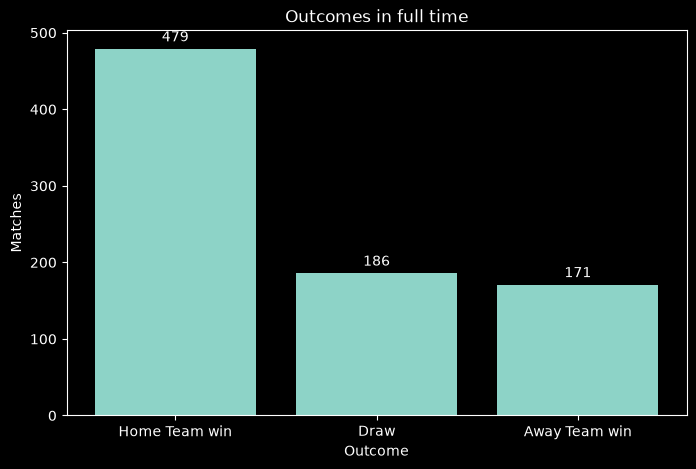

In [19]:
# Note: "Home Team" is only a label from the match schedule, not the tournament host.
home_wins = (data["Home Team Goals"] > data["Away Team Goals"]).sum()
away_wins = (data["Away Team Goals"] > data["Home Team Goals"]).sum()
draws = (data["Home Team Goals"] == data["Away Team Goals"]).sum()

full_time_outcomes = {
    "Home Team win": home_wins,
    "Draw": draws,
    "Away Team win": away_wins
}

plt.figure(figsize=(8, 5))
bars = plt.bar(full_time_outcomes.keys(), full_time_outcomes.values())

plt.title("Outcomes in full time")
plt.xlabel("Outcome")
plt.ylabel("Matches")

plt.bar_label(bars, padding=3)